# 05 — Conditional volatility: ARCH / GARCH (Python, `arch`)

**Project:** *Did Bitcoin miners leave Bitcoin for AI?* — Phase 5. R version: `notebooks/r/05_garch.Rmd` (`rugarch`).

| | |
|---|---|
| **Input** | `data/processed/panel.parquet`, split and pivot from `config.yaml`, models chosen in Phases 3 and 4 |
| **Outputs** | `results/05_*.csv`, `results/forecasts_garch_vol.csv`, `figures/fig_05_*.png` |
| **Brief** | §3.3 (ARCH-LM on ARIMA/VAR residuals, GARCH(1,1) and variants, standardised residual diagnostics, conditional volatility and events), §6 (forecasts h = 5 and 10) |

Returns are expressed **in percent** (100 × log return), because the `arch` optimiser is much more stable at that scale. The comparison and forecasting models are estimated **on the training sample**; the historical volatility curve (section 4) and the pre / post-pivot comparison (section 5) use all available observations, as in Phase 4.

In [1]:
# Resolve the project root from wherever Jupyter was launched, so only relative paths are needed.
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arch
from arch import arch_model
from scipy import stats
from src import config, data, arima, multivariate as mv, garch, plotting

SEED = config.set_seed()   # used by the simulated EGARCH multi-step forecasts
cfg = config.load_config()
plotting.set_style()
pd.set_option("display.width", 190, "display.max_columns", 40, "display.precision", 4)
RES = config.path("results")
warnings.filterwarnings("ignore", category=FutureWarning)
print("root:", ROOT.name, "| seed:", SEED, "| arch", arch.__version__, "| pivot:", cfg["pivot_date"])

root: Bitcoin miners | seed: 42 | arch 9.0.0 | pivot: 2025-01-22


In [2]:
# Percent returns of the four modelled series; train / test and pivot exactly as in phases 3-4.
panel = data.load_panel()
train, test = data.chrono_split(panel)
train_end, PIV = train.index[-1], pd.Timestamp(cfg["pivot_date"])
S = ["CONVERTS", "PURE", "BTC", "NVDA"]
r = pd.DataFrame({s: 100 * panel[f"{s}_log_return"] for s in S}).dropna()
r_tr = r.loc[:train_end]
print(f"returns: {len(r)} | train: {len(r_tr)} ({r_tr.index[0].date()} -> {train_end.date()}) | test: {len(r) - len(r_tr)}")

returns: 1224 | train: 1101 (2021-12-15 -> 2026-05-06) | test: 123


## 1. ARCH-LM test on the residuals of the best ARIMA and VAR models

**ARCH-LM (Engle)** — H0: no ARCH effect, the conditional variance of the residuals is constant. LM statistic = n·R² of the regression of squared residuals on their m lags. Rejected if p < 0.05.

We test the residuals:
* of the **ARIMA(0,1,0)** chosen in Phase 3;
* of each equation of the **VAR(1)** of Phase 4;

all estimated on the training sample. Two additions answer the open questions of Phase 3: CONVERTS returns on the **whole** sample, and each converted stock taken **separately**.

In [3]:
# ARCH-LM on ARIMA(0,1,0) residuals (train) and on each equation of the train VAR(1); m = 5 and 10.
rows = []
for s in ("CONVERTS", "PURE"):
    e = arima.fit_arima(panel[f"{s}_log_price"].loc[:train_end], (0, 1, 0)).resid[1:]
    for m in (5, 10):
        rows.append({"residuals of": f"ARIMA(0,1,0) {s}", "sample": "train", "lag": m, **dict(zip(["LM", "p_value"], arima.arch_lm(e, m)))})
v = mv.fit_var(pd.DataFrame({s: panel[f"{s}_log_return"] for s in ["BTC", "NVDA", "CONVERTS", "PURE"]}).dropna().loc[:train_end], 1)
for s in ["BTC", "NVDA", "CONVERTS", "PURE"]:
    for m in (5, 10):
        rows.append({"residuals of": f"VAR(1) equation {s}", "sample": "train", "lag": m, **dict(zip(["LM", "p_value"], arima.arch_lm(v.resid[s], m)))})
# Open questions from Phase 3: full sample, and each converted stock on its own.
for s in ["CONVERTS", "IREN", "CIFR", "WULF", "MARA", "CLSK", "RIOT"]:
    x = panel[f"{s}_log_return"].dropna()
    for m in (5, 10):
        rows.append({"residuals of": f"return {s} (demeaned)", "sample": "full", "lag": m, **dict(zip(["LM", "p_value"], arima.arch_lm(x - x.mean(), m)))})
archlm = pd.DataFrame(rows)
archlm["conclusion (5%)"] = np.where(archlm["p_value"] < 0.05, "reject H0 (ARCH effect)", "H0 not rejected")
archlm.to_csv(RES / "05_archlm.csv", index=False)
archlm

,residuals of,sample,lag,LM,p_value,conclusion (5%)
0,"ARIMA(0,1,0) CONVERTS",train,5,3.5861,6.1040e-01,H0 not rejected
1,"ARIMA(0,1,0) CONVERTS",train,10,4.5027,9.2183e-01,H0 not rejected
2,"ARIMA(0,1,0) PURE",train,5,16.4243,5.7316e-03,reject H0 (ARCH effect)
3,"ARIMA(0,1,0) PURE",train,10,25.3456,4.7275e-03,reject H0 (ARCH effect)
4,VAR(1) equation BTC,train,5,12.3976,2.9727e-02,reject H0 (ARCH effect)
5,VAR(1) equation BTC,train,10,17.0470,7.3330e-02,H0 not rejected
6,VAR(1) equation NVDA,train,5,9.7810,8.1685e-02,H0 not rejected
7,VAR(1) equation NVDA,train,10,11.4091,3.2655e-01,H0 not rejected
8,VAR(1) equation CONVERTS,train,5,3.8057,5.7772e-01,H0 not rejected
9,VAR(1) equation CONVERTS,train,10,5.1443,8.8133e-01,H0 not rejected


**Conclusion on ARCH effects.**
* **ARIMA(0,1,0) residuals**:
  * CONVERTS: H0 not rejected (p = 0.61 at lag 5, 0.92 at lag 10), **no detectable ARCH effect**;
  * PURE: H0 rejected (p = 0.0057 and 0.0047), **ARCH effect present**.
* **VAR(1) residuals**:
  * ARCH effect for PURE (p = 0.0073 and 0.0045);
  * for BTC, only at lag 5 (p = 0.030; lag 10: p = 0.073);
  * **neither for CONVERTS** (p = 0.58 and 0.88) **nor for NVDA** on the training sample (p = 0.082 and 0.33).
* **Full sample, CONVERTS**: still no ARCH effect (p = 0.51 and 0.86).
* **Stocks one by one**:
  * IREN (p = 0.0021) and WULF (p = 0.015 at lag 5) have an ARCH effect, CIFR does not (p = 0.17);
  * among the pure miners, MARA and CLSK have a strong one (p < 0.001), RIOT does not (p = 0.16).

**Interpretation.** The absence of an ARCH effect in the CONVERTS index does not come from a lack of volatility clusters in each stock: two of the three converts have them. The volatility bursts specific to each company (contracts, capital raises) arrive on **different dates**. Once averaged in the index, they dilute, and only isolated jumps without regular clusters remain.

The brief asks for a GARCH when ARCH-LM rejects. This is the case for PURE and BTC. For CONVERTS, we still estimate the GARCH (it is the target series) and check **honestly** whether it adds anything over a constant variance.

## 2. GARCH(1,1) and variants on CONVERTS returns (training sample)

**Mean equation: a constant.** Phase 3 chose ARIMA(0,1,0), i.e. return = constant + noise, so no AR or MA term is needed.

**Conditional variance:**
* **GARCH(1,1)**: σ²_t = ω + α ε²_{t−1} + β σ²_{t−1}. The α term measures the reaction to shocks, the β term the memory. **Persistence** is α + β, and the half-life of a variance shock is ln 0.5 / ln(α + β).
* **Normal or Student-t distribution** (ν degrees of freedom): Phase 3 showed fat tails.
* **GJR-GARCH** adds γ ε²_{t−1}·1(ε_{t−1} < 0): does a **negative** shock raise volatility more than a positive one (leverage effect)?
* **EGARCH** models ln σ²_t, which allows asymmetry without a positivity constraint. Here persistence is β.
* **GARCH(2,1)** is estimated only if the GARCH(1,1) diagnostics leave a residual ARCH effect (brief).

Each model is also compared with a **constant variance** (Student-t). The likelihood-ratio test has H0: α = β = 0. It is slightly conservative, because under H0 the parameter β is not identified and α is on the boundary of its domain.

In [4]:
# Fit every specification on the TRAIN returns of all four series; one comparison table, CONVERTS first.
comp, fits = [], {}
for s in S:
    # Each GARCH is compared with a constant-variance model with the SAME error law (nested models, valid LR test).
    consts = {d: arch_model(r_tr[s], mean="Constant", vol="Constant", dist=d).fit(disp="off") for d in ("normal", "t")}
    for name in garch.SPECS:
        res = garch.fit(r_tr[s], name)
        fits[(s, name)] = res
        const = consts["normal" if name.endswith("-N") else "t"]
        row = garch.summary_row(res, name)
        lr = 2 * (res.loglikelihood - const.loglikelihood)
        row.update({"series": s, "LR vs constant variance": lr, "p(LR)": stats.chi2.sf(lr, len(res.params) - len(const.params))})
        comp.append(row)
    for d, lab in (("normal", "constant variance-N"), ("t", "constant variance-t")):
        c = consts[d]
        comp.append({"series": s, "model": lab, "n": int(c.nobs), "loglik": c.loglikelihood, "AIC": c.aic, "BIC": c.bic})
comp = pd.DataFrame(comp)
comp.to_csv(RES / "05_garch_comparison.csv", index=False)
cols = ["series", "model", "loglik", "AIC", "BIC", "persistence", "half-life (d)", "LR vs constant variance", "p(LR)"]
comp[cols].round(4)

,series,model,loglik,AIC,BIC,persistence,half-life (d),LR vs constant variance,p(LR)
0,CONVERTS,"GARCH(1,1)-N",-3588.0968,7184.1936,7204.2095,0.9698,22.6006,6.5234,0.0383
1,CONVERTS,"GARCH(1,1)-t",-3578.7175,7167.4349,7192.4548,0.9685,21.6617,7.0705,0.0292
2,CONVERTS,"GJR-GARCH(1,1)-t",-3578.2354,7168.4709,7198.4947,0.9718,24.1997,8.0345,0.0453
3,CONVERTS,"EGARCH(1,1)-t",-3573.1880,7158.3759,7188.3998,0.9850,45.7721,18.1295,0.0004
4,CONVERTS,constant variance-N,-3591.3585,7186.7169,7196.7249,NaN,NaN,NaN,NaN
5,CONVERTS,constant variance-t,-3582.2527,7170.5054,7185.5173,NaN,NaN,NaN,NaN
6,PURE,"GARCH(1,1)-N",-3506.8165,7021.6329,7041.6488,0.9534,14.5304,18.7245,0.0001
7,PURE,"GARCH(1,1)-t",-3501.9504,7013.9007,7038.9206,0.9733,25.6041,16.5566,0.0003
8,PURE,"GJR-GARCH(1,1)-t",-3501.9394,7015.8789,7045.9027,0.9719,24.3382,16.5785,0.0009
9,PURE,"EGARCH(1,1)-t",-3502.0518,7016.1036,7046.1274,0.9719,24.2936,16.3538,0.0010


In [5]:
# Parameters with p-values for CONVERTS (and saved for the Python-vs-R comparison in 05_garch.Rmd).
par = []
for name in garch.SPECS:
    res = fits[("CONVERTS", name)]
    for k in res.params.index:
        par.append({"model": name, "parameter": k, "estimate": res.params[k], "std_err": res.std_err[k], "p_value": res.pvalues[k],
                    "loglik": res.loglikelihood})
par = pd.DataFrame(par)
par.to_csv(RES / "05_garch_python_params.csv", index=False)
par.pivot_table(index="parameter", columns="model", values="estimate", sort=False).round(4)

model,"GARCH(1,1)-N","GARCH(1,1)-t","GJR-GARCH(1,1)-t","EGARCH(1,1)-t"
parameter,,,,
mu,0.1105,0.0601,0.0468,-0.3022
omega,1.2216,1.2705,1.1516,0.0554
alpha[1],0.0090,0.0150,0.0062,-0.0523
beta[1],0.9608,0.9535,0.9594,0.9850
nu,NaN,11.2386,11.4024,10.4637
gamma[1],NaN,NaN,0.0124,-0.0157


**Comparison for CONVERTS (training sample):**

| Model | log-likelihood | AIC | BIC | α + β (persistence) | LR vs constant variance (p) |
|---|---|---|---|---|---|
| Constant variance, Student-t | −3,582.25 | 7,170.51 | **7,185.52** | — | — |
| GARCH(1,1)-N | −3,588.10 | 7,184.19 | 7,204.21 | 0.970 | 6.52 (0.038) |
| **GARCH(1,1)-t** | −3,578.72 | 7,167.43 | 7,192.45 | 0.969 | 7.07 (0.029) |
| GJR-GARCH(1,1)-t | −3,578.24 | 7,168.47 | 7,198.49 | 0.972 | 8.03 (0.045) |
| EGARCH(1,1)-t | −3,573.19 | 7,158.38 | 7,188.40 | 0.985 | 18.13 (0.0004) |

* **A volatility that barely moves.** In the GARCH(1,1)-t of CONVERTS, the reaction to shocks is tiny and **not significant** (α = 0.015, p = 0.13), while memory is strong (β = 0.954). CONVERTS volatility hardly reacts to the previous day's shocks: it drifts slowly around its mean. This is consistent with the non-significant ARCH-LM.
* **The GARCH gain over a constant variance is small.**
  * The LR test narrowly rejects constant variance (p = 0.029), and this test is conservative.
  * AIC slightly prefers GARCH-t (difference of 3.1).
  * **BIC prefers constant variance** (7,185.5 vs 7,192.5).
* **The Student-t distribution is clearly better than the normal** (AIC 7,167 vs 7,184). The estimated ν range from 11 to 12 for the miner indices and are ≈ 3.5 for BTC: its tails are very fat.
* **No asymmetry for CONVERTS.** In the GJR, γ = 0.012 (p = 0.28): a negative shock does not raise volatility more than a positive one. NVDA, on the other hand, shows a clear leverage effect (γ = 0.079 in its GJR, see `05_garch_comparison.csv`).
* **EGARCH: best AIC and BIC on the surface, but a degenerate solution.**
  * Its size effect is **negative** (α = −0.052): a large shock would **lower** volatility, which makes no economic sense.
  * Its mean constant (−0.30% per day) is very far from the observed mean.
  * Its standard errors are almost zero (8·10⁻⁸ for ω), a sign of a degenerate optimiser solution.
  * `rugarch` (R notebook) finds a regular solution for the same model, with a positive size effect and a log-likelihood identical to the GARCH-t's.
  * The variance it forecasts collapses on the test set (see section 6).
* **GARCH(2,1)** is not estimated: the standardised residuals of the GARCH(1,1) show no remaining ARCH effect (section 3), so the brief does not justify it. The exploratory fit gave α₁ = 0 anyway.
* **For PURE, BTC and NVDA, GARCH is clearly justified**: LR p ≤ 0.0003, and AIC and BIC both prefer it to constant variance. GARCH-t persistence: 0.973 (PURE), 0.968 (BTC), 0.985 (NVDA).

**Chosen model: GARCH(1,1)-t**, for all series. It is the model asked for by the brief, the simplest, stable, and its Student-t distribution is justified. For CONVERTS, we note that it **does hardly better than a constant variance**.

## 3. Diagnostics of the standardised residuals z_t = ε_t / σ_t

If volatility is well modelled, the z_t should:
* no longer be autocorrelated;
* no longer have autocorrelation in their squares;
* follow the assumed distribution.

Tests:
* **Ljung-Box on z** — H0: no autocorrelation;
* **Ljung-Box on z²** and **ARCH-LM on z** — H0: no **remaining** conditional heteroscedasticity;
* **Kolmogorov-Smirnov** — H0: z follows the assumed distribution (standardised Student-t(ν)).

Model diagnosed: the **GARCH(1,1)-t** (see the choice in section 2), for CONVERTS, PURE and BTC.

figures\fig_05_01_qq_std_resid.png


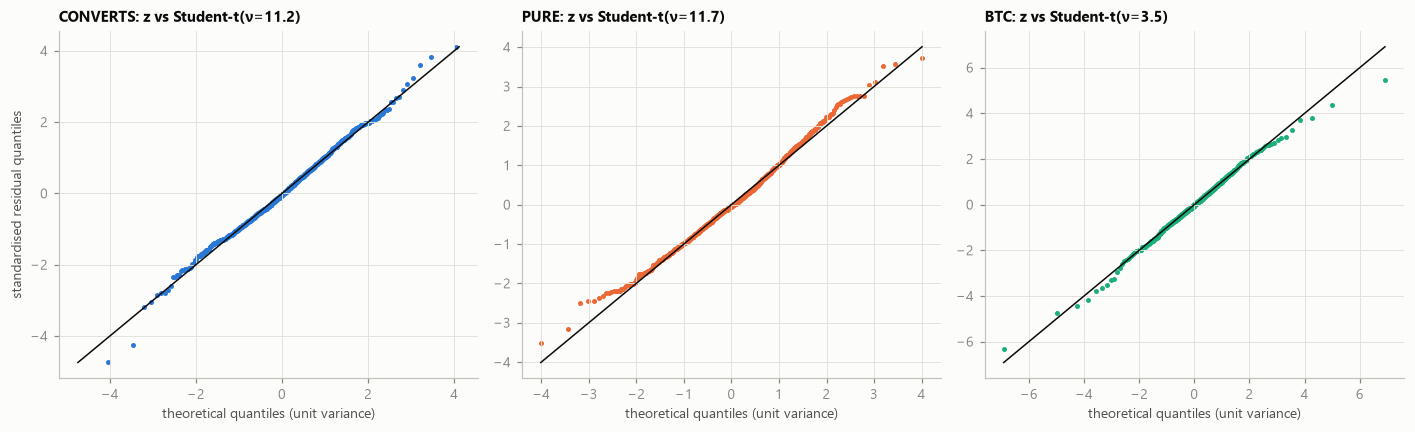

,series,test,parameter,statistic,p_value,conclusion (5%)
0,CONVERTS,Ljung-Box on z,lag 10,11.6419,3.0974e-01,H0 not rejected
1,CONVERTS,Ljung-Box on z,lag 20,15.3155,7.5808e-01,H0 not rejected
2,CONVERTS,Ljung-Box on z²,lag 10,4.6893,9.1094e-01,H0 not rejected
3,CONVERTS,Ljung-Box on z²,lag 20,10.1997,9.6441e-01,H0 not rejected
4,CONVERTS,ARCH-LM on z,lag 5,2.6648,7.5150e-01,H0 not rejected
5,CONVERTS,ARCH-LM on z,lag 10,4.7117,9.0959e-01,H0 not rejected
6,CONVERTS,Kolmogorov-Smirnov vs Student-t(ν),ν = 11.2,0.0604,6.2119e-04,reject H0
7,PURE,Ljung-Box on z,lag 10,11.7127,3.0474e-01,H0 not rejected
8,PURE,Ljung-Box on z,lag 20,18.7567,5.3769e-01,H0 not rejected
9,PURE,Ljung-Box on z²,lag 10,10.3997,4.0616e-01,H0 not rejected


In [6]:
# Diagnostics of the chosen model on three series, plus the QQ-plots against the assumed Student-t.
CHOSEN = "GARCH(1,1)-t"
dz = pd.concat([garch.std_resid_diagnostics(fits[(s, CHOSEN)]).assign(series=s) for s in ("CONVERTS", "PURE", "BTC")], ignore_index=True)
dz = dz[["series", "test", "parameter", "statistic", "p_value", "conclusion (5%)"]]
dz.to_csv(RES / "05_std_resid_diagnostics.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, s in zip(axes, ("CONVERTS", "PURE", "BTC")):
    th, z = garch.qq_points(fits[(s, CHOSEN)])
    ax.scatter(th, z, s=5, color=plotting.CORE[s]); lim = [min(th.min(), z.min()), max(th.max(), z.max())]
    ax.plot(lim, lim, color=plotting.INK, lw=1)
    ax.set_title(f"{s}: z vs Student-t(ν={fits[(s, CHOSEN)].params['nu']:.1f})"); ax.set_xlabel("theoretical quantiles (unit variance)")
axes[0].set_ylabel("standardised residual quantiles")
fig.tight_layout(); print(plotting.save(fig, "fig_05_01_qq_std_resid")); plt.show()
dz

**Conclusions for the GARCH(1,1)-t:**
* **Ljung-Box on z**: H0 not rejected for the three series (CONVERTS p = 0.31 and 0.76; PURE 0.30 and 0.54; BTC 0.82 and 0.61). The standardised residuals are not autocorrelated.
* **Ljung-Box on z² and ARCH-LM on z**: H0 not rejected anywhere. CONVERTS: p = 0.91 and 0.96 for z², 0.75 and 0.91 for ARCH-LM. **PURE**, which had a clear ARCH effect before modelling (p = 0.006): p = 0.41 and 0.82 for z², 0.22 and 0.37 for ARCH-LM. BTC: p ≥ 0.51. **The conditional heteroscedasticity is gone**, as the brief requires.
* **Assumed distribution (Kolmogorov-Smirnov vs standardised Student-t(ν))**: H0 rejected for the three series (CONVERTS p = 0.0006, PURE p = 0.0035, BTC p ≈ 8·10⁻³³). The exact shape of the distribution is therefore not perfect. The QQ-plots show that:
  * for CONVERTS and PURE, the departure stays moderate (the KS test is very sensitive with 1,101 observations);
  * for BTC, the departure is clear: a spike of values close to zero (the calm days) and tails even fatter than the Student(3.5).

  This is a limitation to report: forecast intervals based on the Student-t remain approximate for BTC.

## 4. Conditional volatility and events

GARCH(1,1)-t estimated on the **whole** sample of each series (descriptive use), annualised volatility σ_t·√252. The annotated events were **checked in the press** (sources below). No date is guessed.

| # | Date | Event | Source |
|---|---|---|---|
| 1 | 2022-11-09 | Binance backs out of buying FTX, BTC at its lowest since 2020 (FTX bankruptcy) | [The Block](https://www.theblock.co/post/184636/binance-backs-out-of-ftx-acquisition-deal), [Fortune](https://fortune.com/crypto/2022/11/10/bitcoin-plunges-multi-year-low-cz-binance-pulls-out-deal-rescue-sam-bankman-fried-ftx-exchange/) |
| 2 | 2024-01-10 | The SEC approves 11 spot Bitcoin ETFs | [The Block](https://www.theblock.co/post/271324/the-sec-said-it-has-approved-proposals-for-spot-bitcoin-etfs-on-an-accelerated-basis) |
| 3 | 2025-01-27 | DeepSeek shock: NVDA loses ≈ 17% and ≈ $590bn of market value | [Bloomberg](https://www.bloomberg.com/news/articles/2025-01-27/asml-sinks-as-china-ai-startup-triggers-panic-in-tech-stocks), [Fortune](https://fortune.com/2025/01/27/nvidia-deepseek-rout-tech-stocks/) |
| 4 | 2025-08-14 | TeraWulf signs with Fluidstack (AI/HPC), Google backstops the lease | [The Block](https://www.theblock.co/post/366959/bitcoin-miner-terawulf-shares-jump-50-after-google-secures-8-stake-as-part-of-3-7-billion-10-year-ai-compute-deal) |
| 5 | 2025-11-03 | IREN signs a $9.7bn AI cloud contract with Microsoft | [IREN (press release)](https://iren.gcs-web.com/news-releases/news-release-details/iren-secures-97bn-ai-cloud-contract-microsoft) |
| 6 | 2026-02-05 | BTC falls below $70,000 (crash, liquidations) | [The Block](https://www.theblock.co/post/388759/bitcoin-sees-flash-crash-60000), [Bloomberg](https://www.bloomberg.com/news/videos/2026-02-05/bitcoin-crashes-below-70-000-as-collapse-continues-video) |

*Sources consulted on 2026-11-12.*

figures\fig_05_02_conditional_vol_events.png


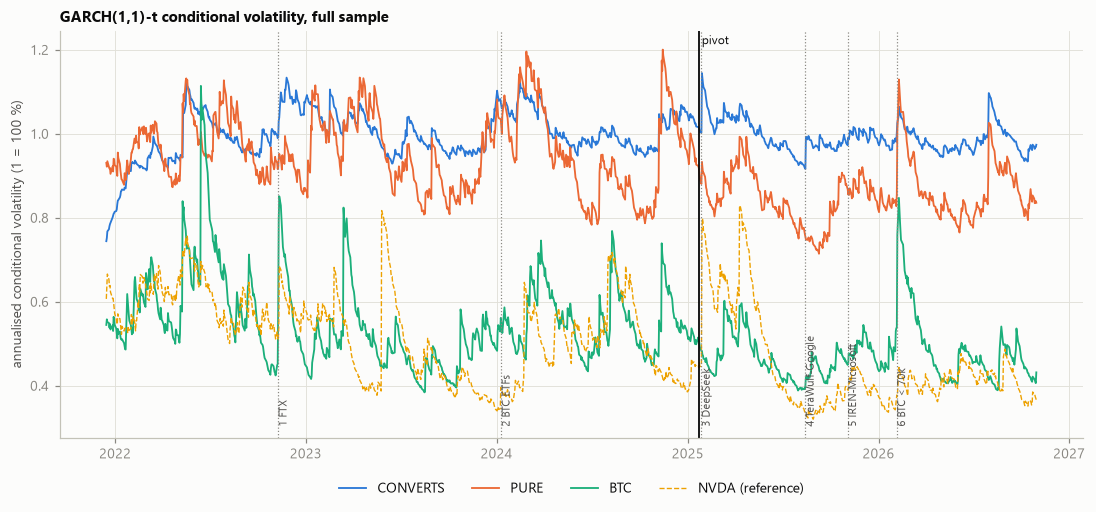

series,CONVERTS,PURE,BTC,NVDA
event,,,,
1 FTX,0.053,0.007,0.766,0.177
2 BTC ETFs,-0.013,0.004,0.025,0.081
3 DeepSeek,0.088,-0.004,-0.056,0.600
4 TeraWulf-Google,0.056,-0.028,0.059,-0.041
5 IREN-Microsoft,0.003,-0.029,0.012,0.045
6 BTC < 70k,0.058,0.240,0.502,0.178


In [7]:
# Full-sample GARCH(1,1)-t per series, annualised conditional volatility, pivot and sourced events on one chart.
EVENTS = {"2022-11-09": "1 FTX", "2024-01-10": "2 BTC ETFs", "2025-01-27": "3 DeepSeek",
          "2025-08-14": "4 TeraWulf-Google", "2025-11-03": "5 IREN-Microsoft", "2026-02-05": "6 BTC < 70k"}
full = {s: garch.fit(r[s], CHOSEN) for s in S}
cvol = pd.DataFrame({s: full[s].conditional_volatility * np.sqrt(252) / 100 for s in S})
cvol.to_csv(RES / "05_conditional_vol_full.csv")
fig, ax = plt.subplots(figsize=(12, 4.8))
for s in ("CONVERTS", "PURE", "BTC"):
    ax.plot(cvol.index, cvol[s], color=plotting.CORE[s], lw=1.2, label=s)
ax.plot(cvol.index, cvol["NVDA"], color=plotting.CORE["NVDA"], lw=0.9, ls="--", label="NVDA (reference)")
ax.axvline(PIV, color=plotting.INK, lw=1.2); ax.text(PIV, 0.99, " pivot", transform=ax.get_xaxis_transform(), va="top", fontsize=8)
for d, lab in EVENTS.items():
    ax.axvline(pd.Timestamp(d), color=plotting.MUTED, lw=0.8, ls=":")
    ax.text(pd.Timestamp(d), 0.02, f" {lab}", rotation=90, transform=ax.get_xaxis_transform(), fontsize=7.5, color=plotting.INK2, va="bottom")
ax.set_ylabel("annualised conditional volatility (1 = 100 %)"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)
ax.set_title("GARCH(1,1)-t conditional volatility, full sample")
print(plotting.save(fig, "fig_05_02_conditional_vol_events")); plt.show()
# Volatility level around each event: average of the 5 days before vs the 5 days from the event on.
ev = []
for d, lab in EVENTS.items():
    i = cvol.index.get_indexer([pd.Timestamp(d)], method="bfill")[0]
    for s in ("CONVERTS", "PURE", "BTC", "NVDA"):
        ev.append({"event": lab, "series": s, "vol before (5 d)": cvol[s].iloc[i - 5:i].mean(), "vol after (5 d)": cvol[s].iloc[i:i + 5].mean()})
ev = pd.DataFrame(ev); ev["change"] = ev["vol after (5 d)"] / ev["vol before (5 d)"] - 1
ev.to_csv(RES / "05_vol_around_events.csv", index=False)
ev.pivot_table(index="event", columns="series", values="change", sort=False)[["CONVERTS", "PURE", "BTC", "NVDA"]].round(3)

**Reading the chart and the change in volatility around events** (mean of the 5 days after vs the 5 days before):

| Event | CONVERTS | PURE | BTC | NVDA |
|---|---|---|---|---|
| 1 FTX (crypto crisis) | +5% | +1% | **+77%** | +18% |
| 3 DeepSeek (AI shock) | **+9%** | −0% | −6% | **+60%** |
| 6 BTC < $70,000 (crypto shock) | +6% | **+24%** | **+50%** | +18% |

* **Levels.** The two miner indices have an annualised volatility of ≈ 80 to 120%, about twice that of BTC and NVDA (≈ 35 to 80%). BTC's peaks are crypto crises (FTX, February 2026), NVDA's are AI shocks (DeepSeek) or earnings releases.
* **Crypto shocks hit the pure miners, AI shocks hit the converts.**
  * After the FTX crisis, only BTC's volatility (+77%) really jumps.
  * After the BTC fall in February 2026, **PURE** reacts clearly (+24%), CONVERTS much less (+6%).
  * After the **DeepSeek shock**, on the contrary, it is **CONVERTS** that reacts (+9%), while PURE does not move.

  The CONVERTS GARCH reacts little to any shock (α ≈ 0.015), so the relative ordering matters here more than the size. This profile points the same way as Phase 4: after the pivot, the converts became sensitive to AI.
* **AI deal announcements** (4 TeraWulf–Google: +6%; 5 IREN–Microsoft: +0%) do not durably raise the index's volatility. 14 August 2025 is a large isolated positive return (Phase 2), not the start of a turbulent period.
* **These changes are descriptive**: they are computed on a model estimated on the whole sample, and without a statistical test.

## 5. After the pivot, does the converts' volatility look more like BTC's or like NVDA's?

Two complementary angles:
1. **GARCH(1,1)-t parameters before / after the pivot** for the four series: reaction α, memory β, persistence α + β. They are compared with their standard errors, because a poorly identified parameter cannot be compared.
2. **Co-movement of volatilities**: correlation of **absolute** returns |r| (a simple measure of the day's volatility) between CONVERTS and BTC, and between CONVERTS and NVDA, before and after the pivot. PURE is the control. This measure depends on no model, so it stays valid even if the GARCH is poorly identified.

In [8]:
# GARCH(1,1)-t on each regime, all observations of the regime (inference, like Phase 4).
pp = []
for s in S:
    for lab, x in [("pre-pivot", r.loc[:PIV - pd.Timedelta(days=1), s]), ("post-pivot", r.loc[PIV:, s])]:
        res = garch.fit(x, CHOSEN)
        p_, se = res.params, res.std_err
        pers = garch.persistence(res)
        pp.append({"series": s, "period": lab, "n": len(x), "alpha": p_["alpha[1]"], "se(alpha)": se["alpha[1]"],
                   "beta": p_["beta[1]"], "se(beta)": se["beta[1]"], "persistence": pers, "half-life (d)": garch.half_life(pers),
                   "nu": p_["nu"], "identified": bool(se["beta[1]"] < 0.5 * abs(p_["beta[1]"]) if p_["beta[1]"] > 0 else False)})
pp = pd.DataFrame(pp)
pp.to_csv(RES / "05_persistence_pre_post.csv", index=False)
pp.round(4)

,series,period,n,alpha,se(alpha),beta,se(beta),persistence,half-life (d),nu,identified
0,CONVERTS,pre-pivot,777,0.0236,0.0139,0.9404,0.0284,0.9640,18.9130,11.1620,True
1,CONVERTS,post-pivot,447,0.0000,0.1959,0.7957,0.9744,0.7957,3.0322,13.8677,False
2,PURE,pre-pivot,777,0.0354,0.0203,0.8862,0.0617,0.9216,8.4902,16.8080,True
3,PURE,post-pivot,447,0.0579,0.0766,0.0000,0.2953,0.0579,0.2432,12.0909,False
4,BTC,pre-pivot,777,0.0376,0.0215,0.9383,0.0358,0.9759,28.4209,3.1838,True
5,BTC,post-pivot,447,0.1609,0.1306,0.5067,0.7119,0.6677,1.7159,5.4891,False
6,NVDA,pre-pivot,777,0.0266,0.0124,0.9655,0.0171,0.9921,87.6367,7.0629,True
7,NVDA,post-pivot,447,0.0328,0.0369,0.9257,0.0559,0.9585,16.3544,6.5080,True


In [9]:
# Model-free check: correlation of absolute returns (volatility co-movement), pre vs post, CONVERTS and the PURE control.
ab = r.abs()
ac = []
for lab, idx in [("pre-pivot", ab.index < PIV), ("post-pivot", ab.index >= PIV)]:
    c = ab[idx].corr()
    for g in ("CONVERTS", "PURE"):
        ac.append({"period": lab, "group": g, "corr |r| with BTC": c.loc[g, "BTC"], "corr |r| with NVDA": c.loc[g, "NVDA"]})
ac = pd.DataFrame(ac)
ac.to_csv(RES / "05_absret_corr_pre_post.csv", index=False)
ac.round(3)

,period,group,corr |r| with BTC,corr |r| with NVDA
0,pre-pivot,CONVERTS,0.316,0.063
1,pre-pivot,PURE,0.447,0.150
2,post-pivot,CONVERTS,0.274,0.310
3,post-pivot,PURE,0.397,0.237


**1. Persistence before / after the pivot (GARCH(1,1)-t).**
* **Before the pivot**, all estimates are well identified: persistence 0.964 (CONVERTS), 0.922 (PURE), 0.976 (BTC), 0.992 (NVDA). The converts' volatility was as persistent as BTC's.
* **After the pivot**, only NVDA remains well estimated (0.959; standard error of β = 0.056). For CONVERTS, PURE and BTC, the standard error of β is as large as β itself (CONVERTS: β = 0.80, standard error 0.97), or even α = 0. With α = 0, β is not even identifiable, since the variance becomes constant. `rugarch` confirms: it finds very different values for these three series (0.986 for CONVERTS, 0.999 for PURE). **Comparing persistence after the pivot is therefore not possible** with 447 observations. We say so rather than interpret unstable numbers.

**2. Co-movement of volatilities (correlation of absolute returns), model-free:**

| | corr(|r|, |BTC|) before → after | corr(|r|, |NVDA|) before → after |
|---|---|---|
| CONVERTS | 0.316 → 0.274 | **0.063 → 0.310** |
| PURE (control) | 0.447 → 0.397 | 0.150 → 0.237 |

* **Before the pivot**, the turbulent days of CONVERTS coincided with BTC's (0.32), almost never with NVDA's (0.06).
* **After the pivot**, CONVERTS volatility co-moves **as much or slightly more with NVDA (0.31) than with BTC (0.27)**: the link with NVDA was multiplied by five.
* The PURE control stays **closer to BTC (0.40) than to NVDA (0.24)**. Its rise with NVDA is much more modest and matches the Phase 4 finding: the 2025 AI wave affected all risky assets.

**Answer to question 5:** after the pivot, the converts' volatility **looks as much like NVDA's as like BTC's** (it mostly looked like BTC's before). The pure miners' volatility stays primarily tied to BTC. The GARCH parameters do not settle the persistence question, because after the pivot they are not identified.

In [10]:
# Why EGARCH is not used for forecasting: with train parameters fixed, its one-step variance collapses on the test data.
first_test = r.index[len(r_tr)]
eg = garch.fit(r["CONVERTS"], "EGARCH(1,1)-t", last_obs=first_test)
gt = garch.fit(r["CONVERTS"], "GARCH(1,1)-t", last_obs=first_test)
one = pd.DataFrame({m: x.forecast(horizon=1, start=train_end, reindex=False).variance.iloc[:, 0] for m, x in [("EGARCH-t", eg), ("GARCH-t", gt)]})
print("EGARCH-t size coefficient alpha =", round(eg.params["alpha[1]"], 4), "(p =", round(eg.pvalues["alpha[1]"], 3), ")")
one.describe().loc[["min", "50%", "max"]]

EGARCH-t size coefficient alpha = -0.0523 (p = 0.0 )


,EGARCH-t,GARCH-t
min,1.7633e-30,34.5963
50%,3.2828e-05,37.8140
max,7.4881e-05,48.6080


**Why EGARCH is excluded from the forecasts.** With the parameters estimated on the training sample, the one-day variance forecast by EGARCH-t collapses on the test set: its median is 3·10⁻⁵ %², against 37.8 %² for the GARCH-t (a daily volatility of about 6%). This comes from its negative size effect (α = −0.052): a large shock lowers log σ², which increases the next standardised shock, which lowers log σ² further, and so on. This model is **unstable** and confirms the diagnosis of section 2: a degenerate solution. We therefore keep only the three stable models (GARCH-N, GARCH-t, GJR-t).

## 6. Volatility forecasts h = 5 and h = 10

Same protocol as Phases 3 and 4:
* parameters estimated **on the training sample only**;
* rolling origins over the test set, each forecast seeing only the data known at its origin;
* horizons 1 to 10.

The target is the **variance** of the return on day h, in %²: `y_pred` is the forecast variance, `y_true` the squared return (a noisy but unbiased measure of the true variance). File: `results/forecasts_garch_vol.csv`, common format, no interval.

**Benchmark models:**
* `const_var`: constant variance of the training sample;
* `hist_var20`: variance of the last 20 days, the equivalent of a "random walk" for volatility.

**Error measures:**
* **MSE** on the variance;
* **QLIKE** = r²/σ̂² − ln(r²/σ̂²) − 1. QLIKE is the recommended loss function when the true variance is replaced by r², a noisy measure (Patton, 2011).

In [11]:
# CONVERTS: the three stable GARCH specifications + two benchmarks; PURE and BTC: GARCH(1,1)-t + benchmarks.
H = 10
origins = r.index[len(r_tr) - 1: len(r) - 1]
names = {"GARCH(1,1)-N": "garch_n", "GARCH(1,1)-t": "garch_t", "GJR-GARCH(1,1)-t": "gjr_t"}
parts = []
for s, specs in [("CONVERTS", list(names)), ("PURE", ["GARCH(1,1)-t"]), ("BTC", ["GARCH(1,1)-t"])]:
    for spec in specs:
        f, _ = garch.vol_forecasts(r[s], spec, train_end, origins, H, names[spec], s, seed=SEED)
        parts.append(f)
    parts.append(garch.naive_vol_forecasts(r[s], train_end, origins, H, s))
fcv = pd.concat(parts, ignore_index=True)
fcv.to_csv(RES / "forecasts_garch_vol.csv", index=False, date_format="%Y-%m-%d")
vs = garch.vol_scores(fcv)
vs.to_csv(RES / "05_vol_scores_preview.csv", index=False)
print(f"{len(fcv)} rows, {fcv['origin'].nunique()} origins")
vs.round(4)

13035 rows, 123 origins


,model,series,horizon,n,MSE_var,QLIKE
0,garch_n,CONVERTS,5,119,3438.2382,1.1168
1,garch_n,CONVERTS,10,114,3543.9224,1.1326
2,garch_t,CONVERTS,5,119,3447.1720,1.1191
3,garch_t,CONVERTS,10,114,3549.8965,1.1341
4,gjr_t,CONVERTS,5,119,3439.1937,1.1170
5,gjr_t,CONVERTS,10,114,3537.8822,1.1305
6,const_var,CONVERTS,5,119,3421.2553,1.1119
7,const_var,CONVERTS,10,114,3530.2483,1.1286
8,hist_var20,CONVERTS,5,119,3750.0906,1.2289
9,hist_var20,CONVERTS,10,114,3891.7591,1.2586


figures\fig_05_03_vol_forecasts_converts.png


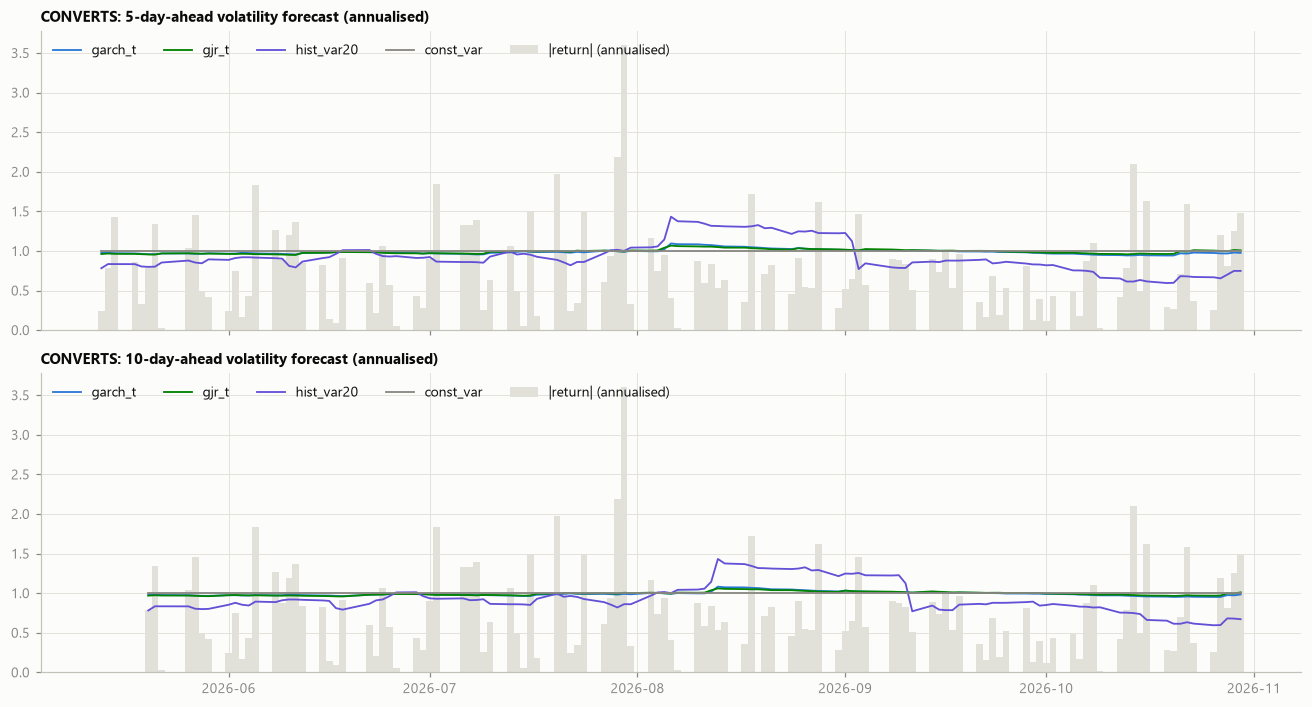

In [12]:
# CONVERTS: 5- and 10-day-ahead volatility forecasts (annualised) vs |return| over the test set.
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, h in zip(axes, (5, 10)):
    k = fcv[(fcv["series"] == "CONVERTS") & (fcv["horizon"] == h)]
    obs = k[k["model"] == "garch_t"]
    ax.bar(obs["date"], np.sqrt(obs["y_true"]) * np.sqrt(252) / 100, color=plotting.GRID, width=1.0, label="|return| (annualised)")
    for m, col in [("garch_t", plotting.CORE["CONVERTS"]), ("gjr_t", plotting.SERIES[5]), ("hist_var20", plotting.SERIES[6]), ("const_var", plotting.MUTED)]:
        g = k[k["model"] == m]
        ax.plot(g["date"], np.sqrt(g["y_pred"]) * np.sqrt(252) / 100, color=col, lw=1.2, label=m)
    ax.set_title(f"CONVERTS: {h}-day-ahead volatility forecast (annualised)"); ax.legend(loc="upper left", ncol=5)
fig.tight_layout(); print(plotting.save(fig, "fig_05_03_vol_forecasts_converts")); plt.show()

**Overview (QLIKE: lower = better; 119 origins at h = 5, 114 at h = 10):**

| Series | Best model by QLIKE (h = 5 / h = 10) | GARCH(1,1)-t | Constant variance | Variance of the last 20 days |
|---|---|---|---|---|
| CONVERTS | **const_var** (1.112 / 1.129) | 1.119 / 1.134 | 1.112 / 1.129 | 1.229 / 1.259 |
| PURE | **garch_t** (1.269 / 1.220) | 1.269 / 1.220 | 1.286 / 1.238 | 1.342 / 1.295 |
| BTC | **garch_t** (1.845 / 1.901) | 1.845 / 1.901 | 1.911 / 1.948 | 2.190 / 2.018 |

* **For CONVERTS, constant variance does as well as or better than every GARCH**, in MSE as in QLIKE. The three GARCH models stay very close to constant variance (fig. 05_03: their curves are almost flat, ≈ 100% annualised). This is the logical consequence of the absence of an ARCH effect in the index.
* **For PURE and BTC, GARCH(1,1)-t beats both benchmarks in QLIKE**, where ARCH-LM had detected an effect. For BTC, the 20-day variance has the smallest MSE but the worst QLIKE. MSE on r² is dominated by a few extreme days, which is why QLIKE is the reference loss here.
* **The 20-day variance is the worst in QLIKE for all three series**: a short window reacts too much to noise.
* **Significance**: tested in Phase 7 (Diebold-Mariano on the QLIKE losses).

## Phase 5 summary

1. **ARCH-LM**: clear ARCH effect for PURE (p = 0.006), BTC, MARA, CLSK, IREN, WULF, but **not for the CONVERTS index** (p = 0.61 on the training sample, 0.51 on the whole sample). The volatility bursts specific to each convert dilute in the average.
2. **Chosen model: GARCH(1,1)-t** (Student-t clearly better than normal). For CONVERTS, α = 0.015 (not significant) and β = 0.954: the gain over a constant variance is small (LR p = 0.029, and BIC prefers constant variance). No asymmetry (GJR γ p = 0.28). EGARCH has a degenerate solution in Python (negative size effect, collapsing forecasts), which R does not reproduce.
3. **Standardised residuals**: no autocorrelation, no remaining ARCH effect (all p ≥ 0.22); the Student-t shape is imperfect (KS rejected, especially for BTC).
4. **Volatility and the pivot**: after the pivot, CONVERTS volatility co-moves as much with NVDA as with BTC (correlation of |r|: 0.06 → 0.31 with NVDA, 0.32 → 0.27 with BTC), while PURE stays primarily tied to BTC. The converts react to the DeepSeek AI shock, the pure miners to BTC crashes. GARCH persistence after the pivot is not identified (447 days).
5. **Volatility forecasts**: for CONVERTS, constant variance is best (QLIKE 1.112 vs 1.119 for GARCH-t at h = 5); for PURE and BTC, GARCH-t is best. R (`rugarch`) confirms the GARCH and GJR models (variance forecast within 0.3%) and corrects the EGARCH.